# Multimodal vs. Image-Only: Results Comparison

Side-by-side comparison of test accuracy, F1 and ROC-AUC for eight pretrained backbones, with and without numerical voice features. Results are loaded from the two earlier notebooks; the test sets differ (n=38 vs. n=30), so differences are indicative only.

In [5]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SAVE_DIR = "model_comparison"   # run notebooks from the notebooks/ folder

with open(os.path.join(SAVE_DIR, "multimodal_results.pkl"), "rb") as f:
    d = pickle.load(f)
results, histories = d["results"], d["histories"]

with open(os.path.join(SAVE_DIR, "image_only_results.pkl"), "rb") as f:
    d = pickle.load(f)
results_img, histories_img = d["results_img"], d["histories_img"]

print("Multimodal:", list(results.keys()))
print("Image-only:", list(results_img.keys()))

Multimodal: ['MobileNetV2', 'VGG16', 'EfficientNetV2B0', 'VGG19', 'ResNet50V2', 'Xception', 'InceptionResNetV2', 'ConvNeXtTiny']
Image-only: ['MobileNetV2', 'VGG16', 'EfficientNetV2B0', 'VGG19', 'ResNet50V2', 'Xception', 'InceptionResNetV2', 'ConvNeXtTiny']


In [6]:
common = [m for m in results if m in results_img]
cmp = pd.DataFrame({
    "multimodal_acc": [results[m]["accuracy"] for m in common],
    "image_only_acc": [results_img[m]["accuracy"] for m in common],
    "multimodal_f1":  [results[m]["f1"] for m in common],
    "image_only_f1":  [results_img[m]["f1"] for m in common],
    "multimodal_auc": [results[m]["roc_auc"] for m in common],
    "image_only_auc": [results_img[m]["roc_auc"] for m in common],
}, index=common)
cmp["delta_f1 (multi - img)"] = cmp["multimodal_f1"] - cmp["image_only_f1"]
display(cmp.round(4))

,multimodal_acc,image_only_acc,multimodal_f1,image_only_f1,multimodal_auc,image_only_auc,delta_f1 (multi - img)
MobileNetV2,0.9211,0.7000,0.9455,0.7273,0.9607,0.7778,0.2182
VGG16,0.8158,0.6000,0.8571,0.3333,0.9214,0.7644,0.5238
EfficientNetV2B0,0.9737,0.7667,0.9825,0.7586,0.9929,0.8400,0.2238
VGG19,0.8947,0.6333,0.9231,0.6667,0.9786,0.7511,0.2564
ResNet50V2,0.8947,0.8333,0.9259,0.8387,0.9786,0.9467,0.0872
Xception,0.9737,0.6667,0.9825,0.6875,0.9893,0.8711,0.2950
InceptionResNetV2,0.9474,0.8000,0.9643,0.8000,0.9893,0.9111,0.1643
ConvNeXtTiny,0.9737,0.8667,0.9818,0.8571,0.9893,0.8978,0.1247


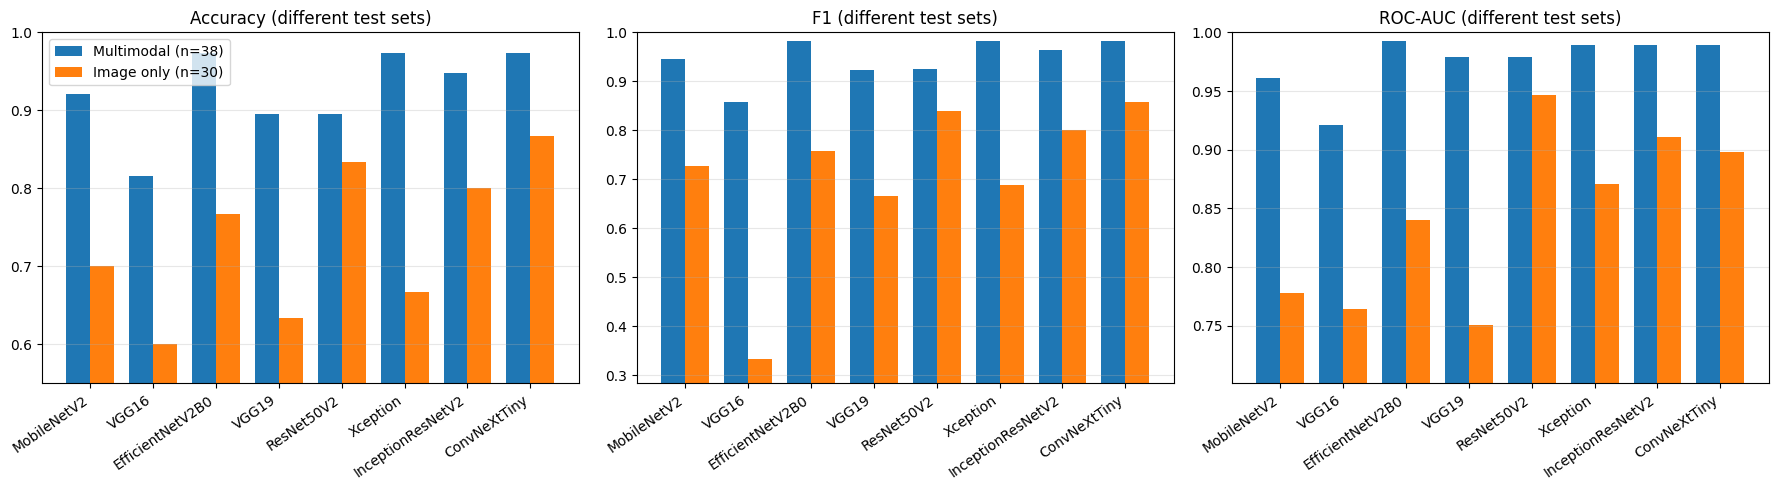

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(len(common)); w = 0.38

for ax, (m_col, i_col, title) in zip(axes, [
        ("multimodal_acc", "image_only_acc", "Accuracy"),
        ("multimodal_f1",  "image_only_f1",  "F1"),
        ("multimodal_auc", "image_only_auc", "ROC-AUC")]):
    ax.bar(x - w/2, cmp[m_col], w, label="Multimodal (n=38)")
    ax.bar(x + w/2, cmp[i_col], w, label="Image only (n=30)")
    ax.set_xticks(x); ax.set_xticklabels(common, rotation=35, ha="right")
    lo = min(cmp[m_col].min(), cmp[i_col].min())
    ax.set_ylim(max(0, lo - 0.05), 1.0)
    ax.set_title(f"{title} (different test sets)")
    ax.grid(axis="y", alpha=0.3)

axes[0].legend()
plt.tight_layout(); plt.show()